# Análise de Cesta Básica

1. Importação e Limpeza
2. Pergunta 1: Análise do Café
3. Pergunta 2: Agrupamentos (mercados de melhores preços)

## 1. Importação e Limpeza

In [262]:
# !pip install pandas
# !pip install matplotlib.pyplot
# !pip install seaborn
# !pip install openpyxl
# !pip install scikit-learn
# !pip install Plotly
# !pip install --upgrade nbformat


In [263]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import plotly.express as px
from re import search
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from scipy.stats import pearsonr

In [264]:
df:pd.DataFrame = pd.read_excel("../data/raw/ICB_DADOS_2026.xlsx")

In [265]:
df.columns

Index(['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco',
       'Quantidade', 'PPK'],
      dtype='str')

In [266]:
# dividir por produto
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
             'Pão Francês',                    'Óleo',
                  'Açúcar',        'Farinha de Trigo',
                  'Feijão',            'Banana Prata',
                   'Leite',                  'Tomate',
                  'Batata',           'Banana Nanica',
       'Carne Bovina Acem',            'Frango Peito',
      'Carne Suína Pernil',        'Frango Sobrecoxa',
                     'Ovo',       'Macarrão com Ovos',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra',                 'Farinha',
                'Macarrão',              'Carne Acem',
        'Carne Coxão Mole',                     'Pão',
            'Carne Pernil',                  'Pernil']
Length: 30, dtype: str

### Limpeza

In [267]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
...,...,...,...,...,...,...,...,...
46259,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
46260,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
46261,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
46262,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [268]:
MIN_MESES = 28

meses_por_estab = df.groupby('Estab')['Mes_Ano_Data'].nunique().sort_values(ascending=False)
estabs_validos = meses_por_estab[meses_por_estab >= MIN_MESES].index

linhas_antes = len(df)
df = df[df['Estab'].isin(estabs_validos)].reset_index(drop=True)

print(f'Mercados mantidos: {len(estabs_validos)} de {len(meses_por_estab)}')
print(f'Linhas removidas: {linhas_antes - len(df)} de {linhas_antes} ({(linhas_antes - len(df)) / linhas_antes:.1%})')
print('\nMercados removidos (meses de histórico):')
print(meses_por_estab[meses_por_estab < MIN_MESES])

Mercados mantidos: 28 de 51
Linhas removidas: 2111 de 46264 (4.6%)

Mercados removidos (meses de histórico):
Estab
SUP_29    18
SUP_30    14
SUP_44     3
SUP_45     2
SUP_10     2
SUP_14     2
SUP_23     2
SUP_09     1
ALT_49     1
SUP_03     1
ALT_48     1
SUP_02     1
SUP_05     1
ALT_28     1
ALT_35     1
ALT_26     1
SUP_25     1
SUP_18     1
SUP_21     1
SUP_31     1
SUP_37     1
SUP_40     1
SUP_42     1
Name: Mes_Ano_Data, dtype: int64


In [269]:
df['Marca'][df['Produto']=='Café'].unique()

array(['Pilão', 'Melita', '3 Corações', 'Caboclo', 'Canecão',
       'São Joaquim', 'Moraes', 'Pelé', 'São', 'União', 'Fort', 'Nescafé',
       nan, '3 corações', 'São Joaquim ', 'Outro'], dtype=object)

Precisamos tratar as marcas 3 corações e São Joaquim.

In [270]:
df.loc[df['Marca'].str.contains('3 corações', case=False, na=False), 'Marca'] = '3 Corações'
df.loc[df['Marca'].str.contains('São Joaquim ', case=False, na=False), 'Marca'] = 'São Joaquim'

In [271]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [272]:
nomes = {
    "Farinha de Trigo": "Farinha",
    "Carne Acem": "Carne Bovina Acem",
    "Pão Francês": "Pão",
    "Macarrão com Ovos": "Macarrão",
    "Carne Coxão Mole": "Carne Bovina Coxão Mole",
    "Carne Pernil": "Pernil",
    "Carne Suína Pernil": "Pernil",
}
df["Produto"] = df["Produto"].replace(nomes)


In [273]:
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
                     'Pão',                  'Açúcar',
                 'Farinha',                  'Feijão',
                    'Óleo',            'Banana Prata',
                   'Leite',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
                  'Pernil',        'Frango Sobrecoxa',
                     'Ovo',                'Macarrão',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra']
Length: 23, dtype: str

In [274]:
duplicadas = df[df.duplicated(keep=False)]

print(f"Linhas repetidas: {df.duplicated().sum()}")
duplicadas.sort_values(["Mes_Ano_Data", "Estab", "Produto"])

Linhas repetidas: 1742


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
1416,2022-10-01,2022-10-24,SUP_38,Farinha,Dona Benta,6.75,1.0,6.750000
1417,2022-10-01,2022-10-24,SUP_38,Farinha,Dona Benta,6.75,1.0,6.750000
2107,2022-11-01,2022-11-21,SUP_24,Banana Prata,NaN,7.99,1.0,7.990000
2108,2022-11-01,2022-11-21,SUP_24,Banana Prata,NaN,7.99,1.0,7.990000
2114,2022-11-01,2022-11-18,SUP_34,Banana Prata,NaN,7.99,1.0,7.990000
...,...,...,...,...,...,...,...,...
41459,2026-05-01,NaT,SUP_50,Óleo,Soya,7.99,0.9,8.877778
41496,2026-05-01,NaT,SUP_50,Óleo,Liza,7.99,0.9,8.877778
41497,2026-05-01,NaT,SUP_50,Óleo,Soya,7.99,0.9,8.877778
42067,2026-06-01,NaT,SUP_04,Feijão,Outro,8.99,1.0,8.990000


In [275]:
df = df.drop_duplicates()

## 2. Pergunta 1: Análise do Café

### Exploração das marcas

In [276]:
df_cafe = df[df['Produto'] == 'Café']
df_cafe = df_cafe.sort_values('Mes_Ano_Data')

In [277]:
df_cafe['Marca'].unique()

array(['Pilão', 'Caboclo', '3 Corações', 'Moraes', 'Pelé', 'Canecão',
       'São Joaquim', 'Melita', 'Nescafé', 'São', 'Fort', 'União', nan,
       'Outro'], dtype=object)

In [278]:
df_cafe.groupby('Marca').count().sort_values('Quantidade', ascending=False)


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Preco,Quantidade,PPK
Marca,,,,,,,
3 Corações,1083,896,1083,1083,1083,1083,1083
Melita,895,757,895,895,895,895,895
Pilão,809,685,809,809,809,809,809
Caboclo,775,646,775,775,775,775,775
Canecão,690,556,690,690,690,690,690
São Joaquim,218,173,218,218,218,218,218
Moraes,172,129,172,172,172,172,172
União,155,121,155,155,155,155,155
Fort,53,33,53,53,53,53,53


In [279]:
df_cafe = df_cafe[df_cafe['Marca'] != 'Nescafé']
df_cafe = df_cafe[df_cafe['Marca'] != 'São'] 

In [280]:
df_cafe

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
49,2022-09-01,2022-09-21,SUP_39,Café,Pilão,25.99,0.5,51.98
229,2022-09-01,2022-09-12,SUP_43,Café,Caboclo,16.90,0.5,33.80
228,2022-09-01,2022-09-26,SUP_24,Café,Caboclo,16.98,0.5,33.96
227,2022-09-01,2022-09-21,SUP_46,Café,3 Corações,16.98,0.5,33.96
226,2022-09-01,2022-09-26,SUP_41,Café,Pilão,16.99,0.5,33.98
...,...,...,...,...,...,...,...,...
43437,2026-08-01,NaT,SUP_24,Café,Caboclo,29.98,0.5,59.96
43436,2026-08-01,NaT,SUP_24,Café,3 Corações,32.90,0.5,65.80
43435,2026-08-01,NaT,SUP_24,Café,Melita,32.99,0.5,65.98
43398,2026-08-01,NaT,SUP_13,Café,Pelé,30.89,0.5,61.78


In [281]:
def plotar_grafico_por_cada_marca(df, marca:list):
    for m in marca:
        df_marca = df[df['Marca'] == m]
        plt.figure(figsize=(10, 6))
        sns.lineplot(data=df_marca, x='Mes_Ano_Data', y='Preco', marker='o')
        plt.title(f'Preço do Café - {m}')
        plt.xlabel('Mês/Ano')
        plt.ylabel('Preço')
        plt.xticks(rotation=45)
        plt.grid()
        plt.tight_layout()
        plt.show()

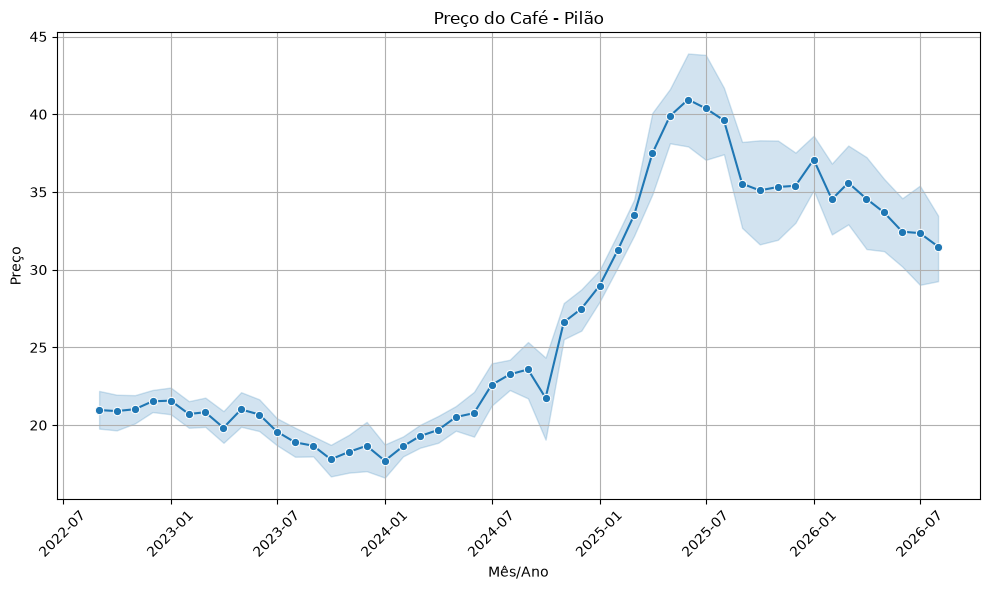

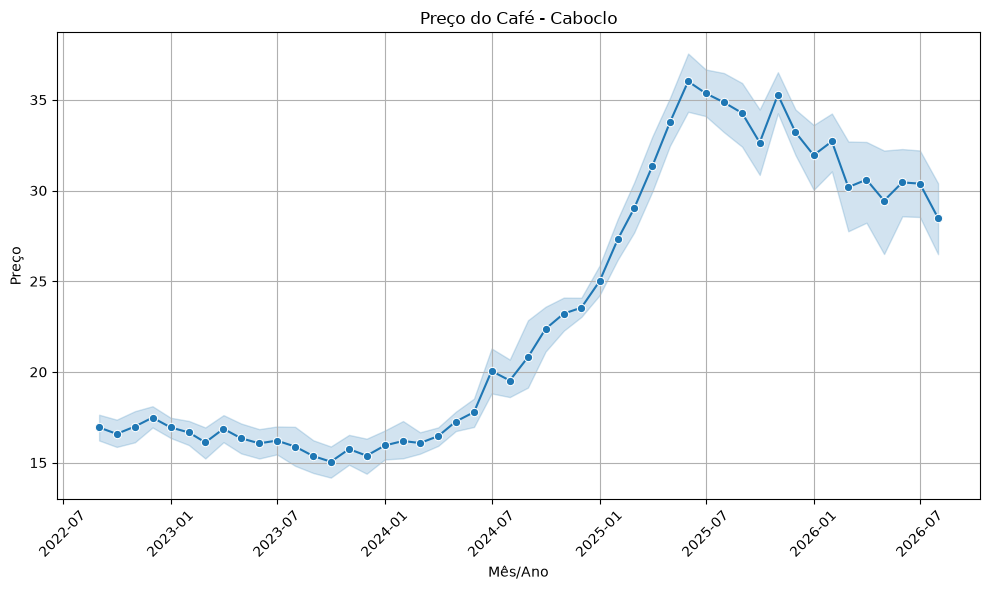

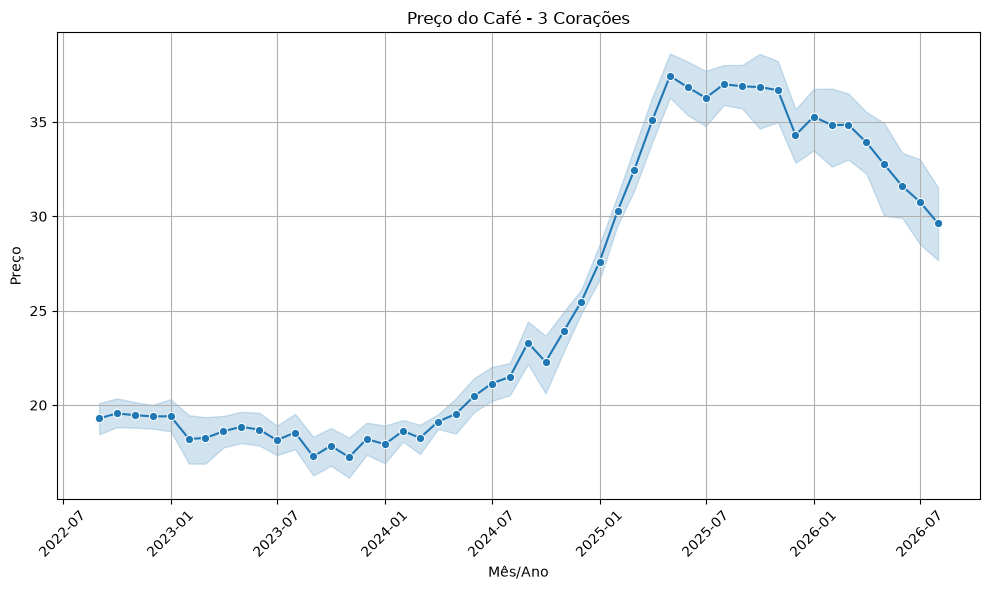

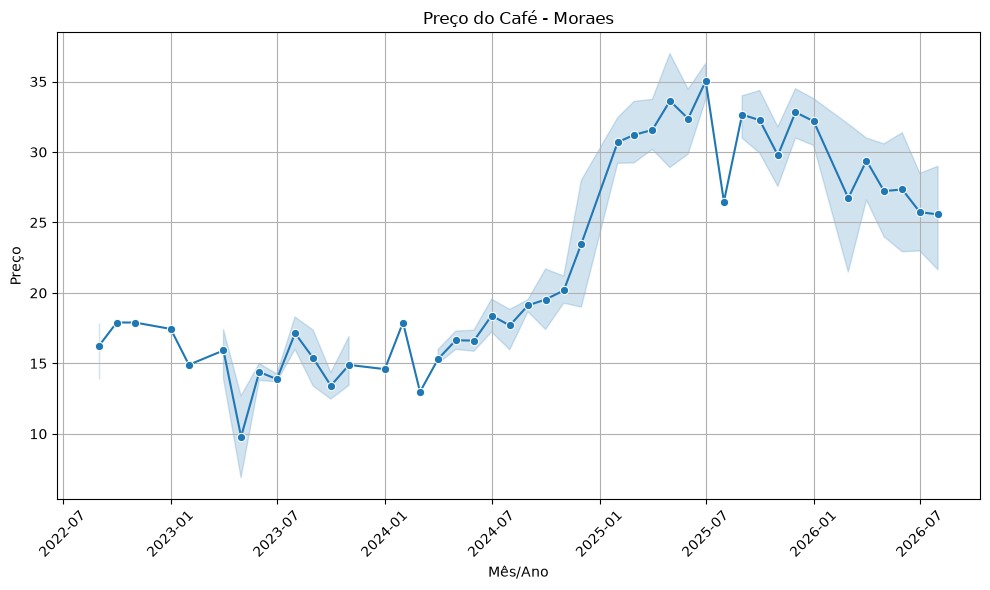

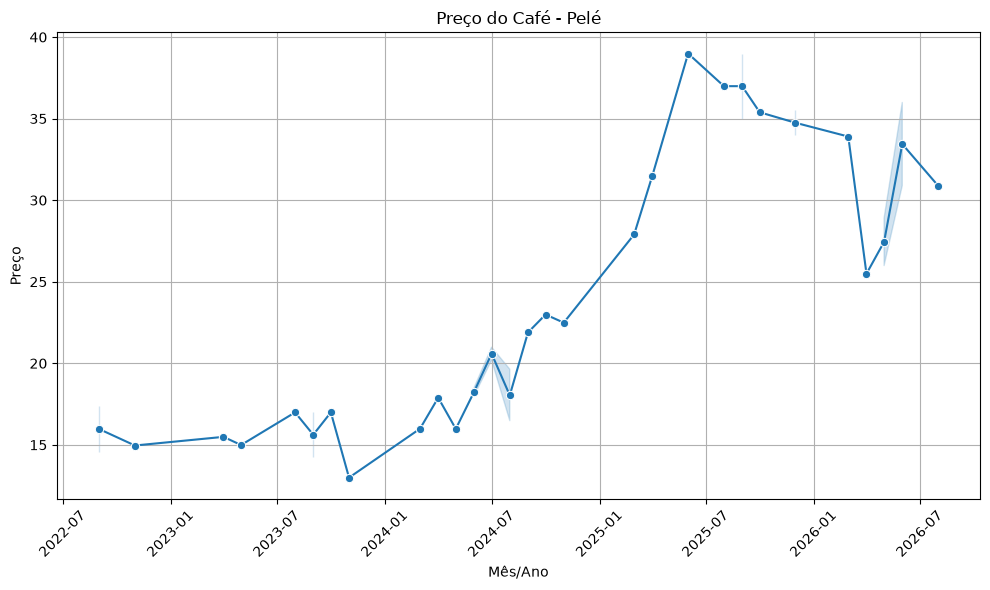

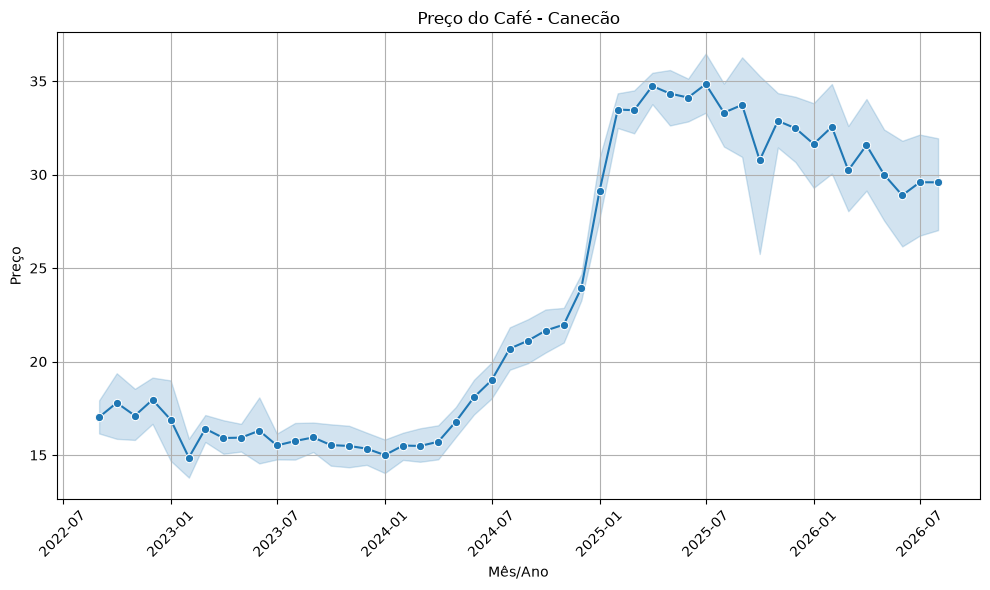

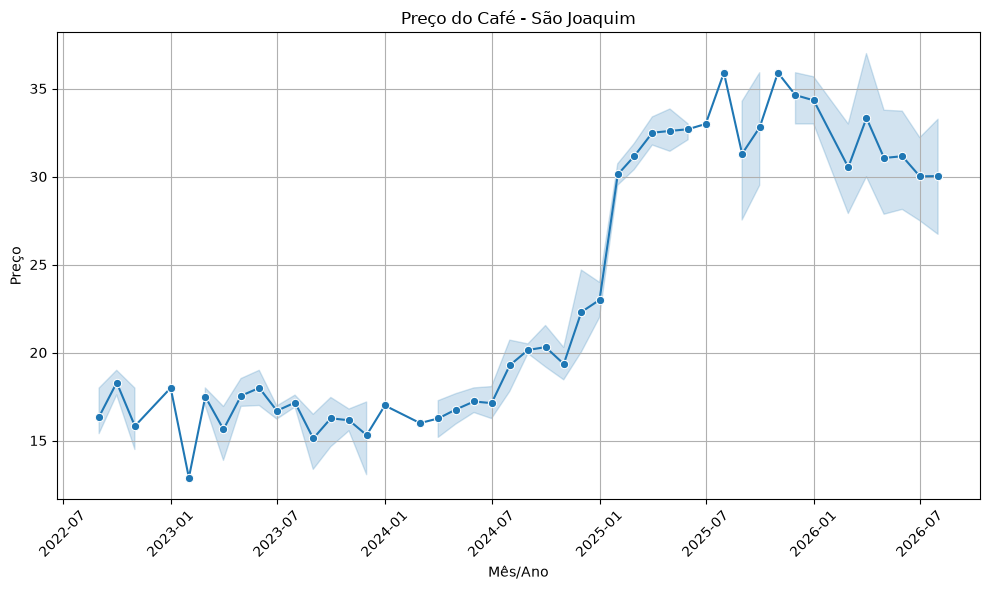

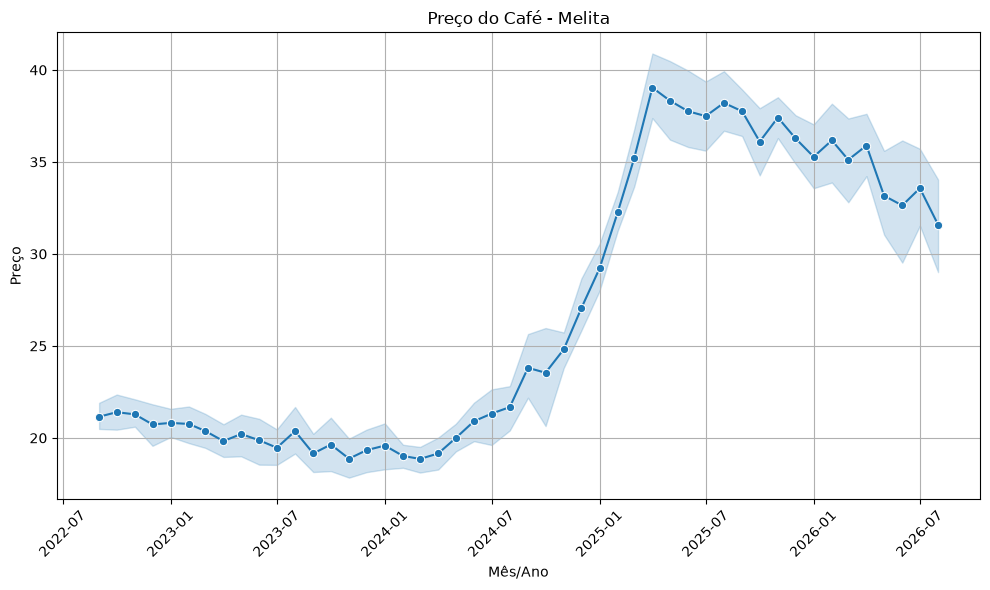

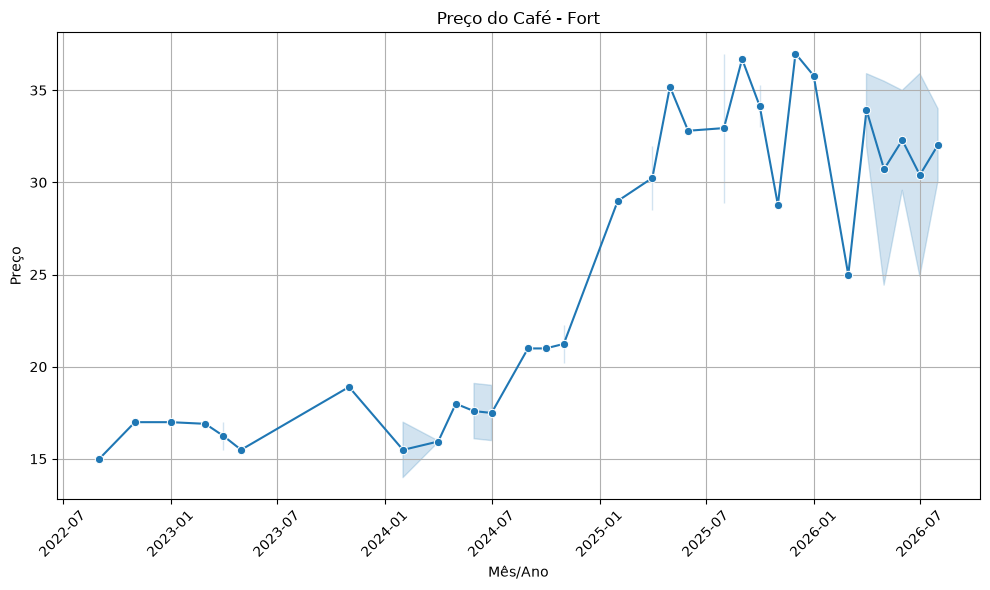

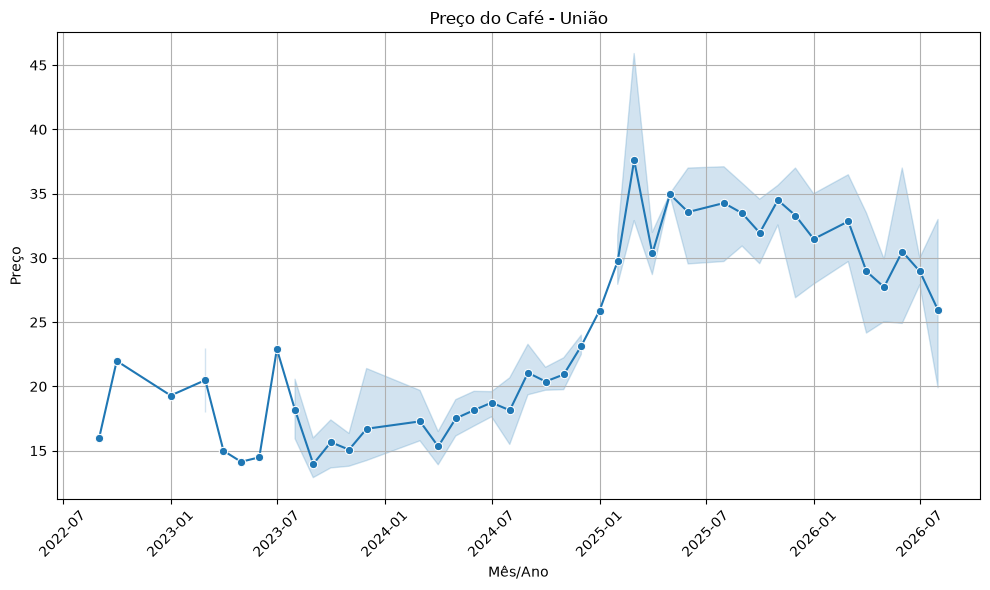

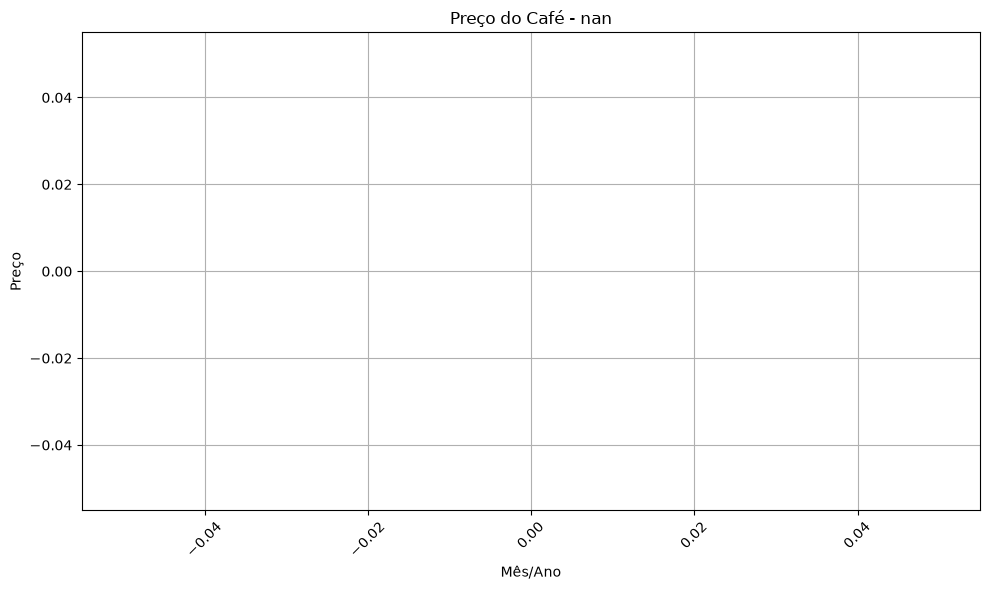

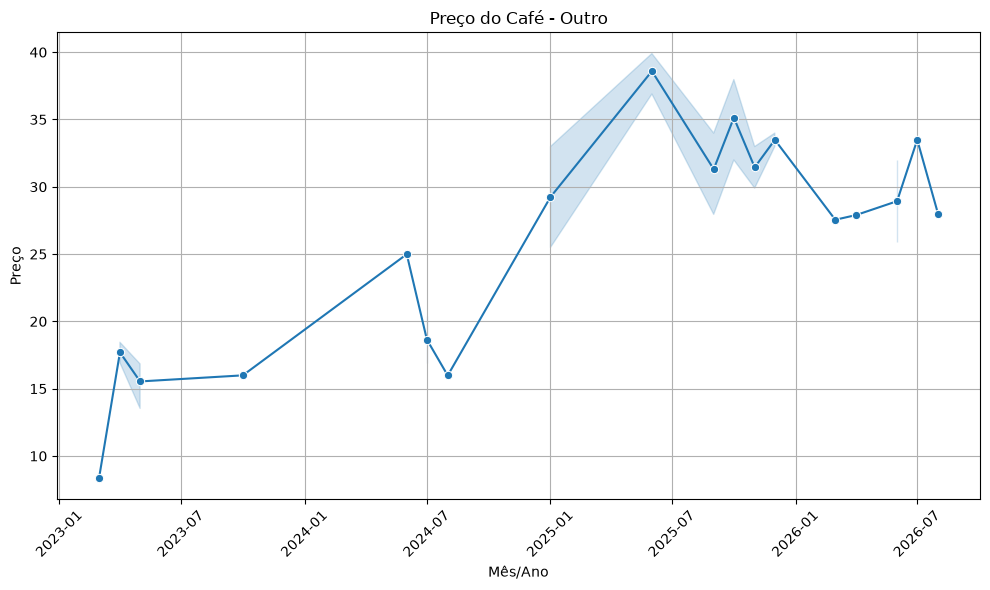

In [282]:
plotar_grafico_por_cada_marca(df_cafe, df_cafe['Marca'].unique())

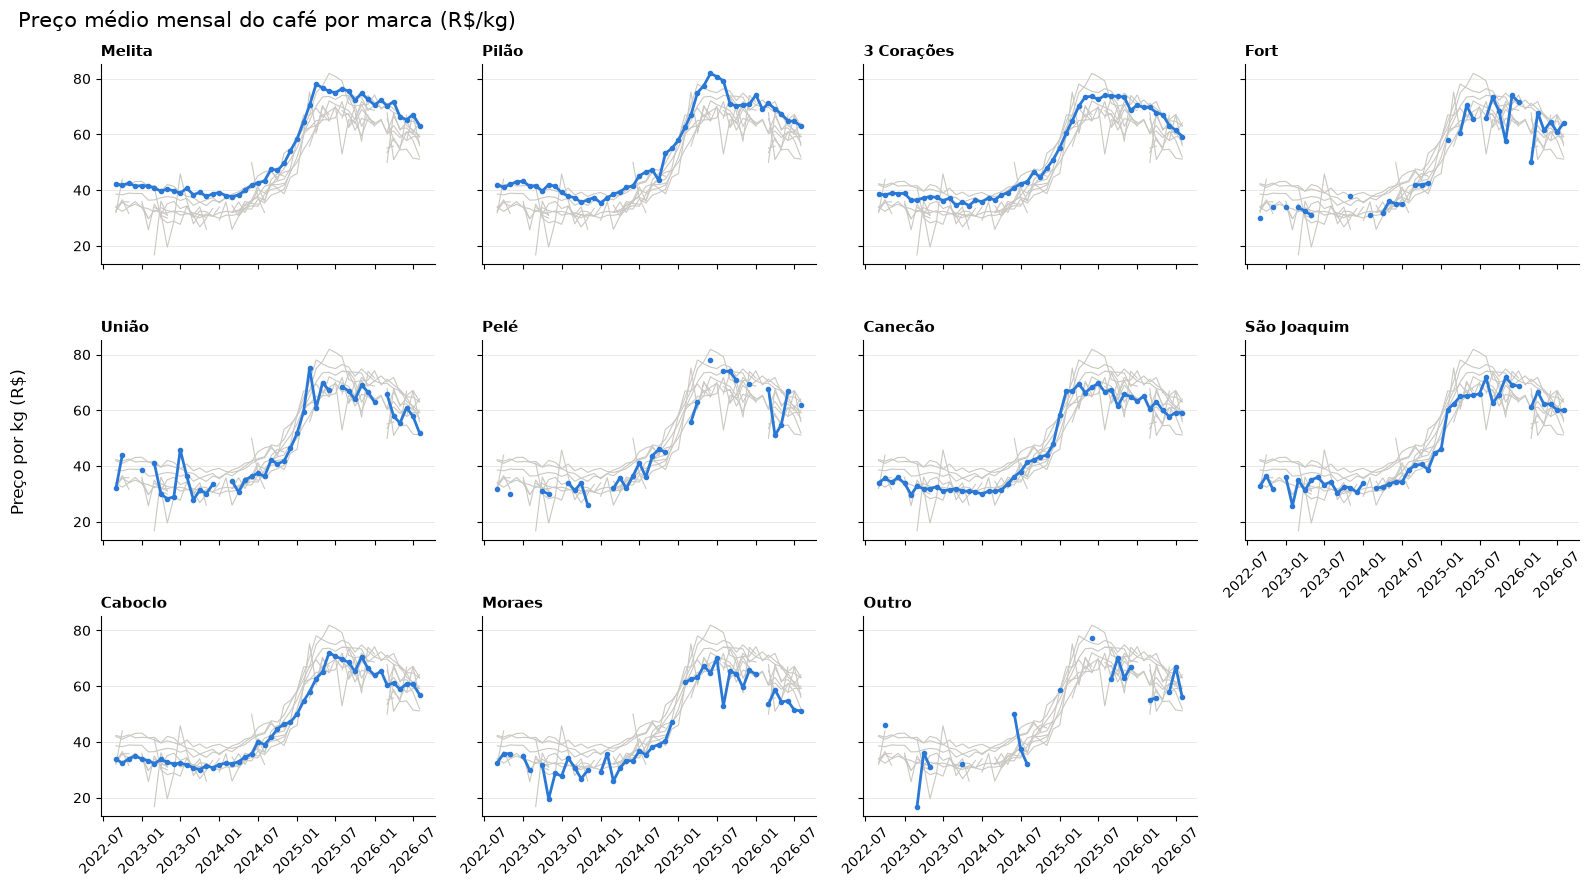

In [283]:
# Padroniza os nomes das marcas (espaços sobrando, maiúsculas/minúsculas, registros incompletos)
marca = df_cafe['Marca'].str.strip().str.title()
marca = marca.replace({'São': 'São Joaquim', 'Nescafé': 'Outro'}).fillna('Outro')

# Média mensal do preço por kg (PPK) de cada marca: uma coluna por marca, uma linha por mês
cafe_mensal = (
    df_cafe.assign(Marca=marca)
    .groupby(['Mes_Ano_Data', 'Marca'])['PPK']
    .mean()
    .unstack('Marca')
)

# Ordena da marca mais cara para a mais barata, deixando "Outro" por último
ordem = cafe_mensal.drop(columns='Outro').mean().sort_values(ascending=False).index.tolist() + ['Outro']

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
for ax, nome in zip(axes.flat, ordem):
    # Todas as marcas em cinza como referência, com a marca do painel em destaque
    ax.plot(cafe_mensal.index, cafe_mensal, color='#c9c8c2', linewidth=0.8)
    ax.plot(cafe_mensal.index, cafe_mensal[nome], color='#2a78d6', linewidth=2, marker='o', markersize=3)
    ax.set_title(nome, loc='left', fontsize=11, fontweight='bold')
    ax.grid(axis='y', color='#e8e7e2', linewidth=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', rotation=45)

# Remove os painéis que sobraram na grade e devolve o eixo de datas ao painel logo acima
for ax in axes.flat[len(ordem):]:
    ax.remove()
axes[1, 3].tick_params(axis='x', labelbottom=True)

fig.suptitle('Preço médio mensal do café por marca (R$/kg)', x=0.01, ha='left', fontsize=15)
fig.supylabel('Preço por kg (R$)', x=0.005)
fig.tight_layout(rect=(0.015, 0, 1, 1))
plt.show()

### Escolha das marcas e série mensal

Tratamento simples para deixar tudo com letra minuscula, filtro para pegar somentes cafes na base e por fim transformando o tipo da data

In [284]:
cafe = df[df["Produto"] == "Café"].copy()
cafe.columns = df.columns.str.lower().str.strip()
cafe.marca = cafe.marca.str.strip()
cafe.marca = cafe.marca.str.lower()
cafe['data_coleta'] = pd.to_datetime(cafe['data_coleta'])

Analisamos a quantidade de cafes por marca para ver se seria bom tirarmos alguns outliers

In [285]:
print(cafe["marca"].value_counts())

marca
3 corações     1083
melita          895
pilão           809
caboclo         775
canecão         690
são joaquim     218
moraes          172
união           155
fort             53
pelé             40
outro            37
são               2
nescafé           1
Name: count, dtype: int64


In [286]:
df_filtro_de_cafe=cafe["marca"].value_counts()
df_filtro_de_cafe =df_filtro_de_cafe.to_frame()
media_dados=df_filtro_de_cafe.mean()
print(media_dados)
std_dados=df_filtro_de_cafe.std()
print(std_dados)

count    379.230769
dtype: float64
count    402.329499
dtype: float64


In [287]:
print(media_dados-std_dados)

count   -23.09873
dtype: float64


In [288]:
df_filtro_de_cafe[df_filtro_de_cafe>(media_dados-2*std_dados)]

,count
marca,
3 corações,1083
melita,895
pilão,809
caboclo,775
canecão,690
são joaquim,218
moraes,172
união,155
fort,53


In [289]:
df_outliers=df_filtro_de_cafe[df_filtro_de_cafe<(media_dados-2*std_dados)]
print(df_outliers)

             count
marca             
3 corações     NaN
melita         NaN
pilão          NaN
caboclo        NaN
canecão        NaN
são joaquim    NaN
moraes         NaN
união          NaN
fort           NaN
pelé           NaN
outro          NaN
são            NaN
nescafé        NaN


Retirando alguns cafes com pouco impacto

Como a média menos 2 desvios padrão deu negativa, o teste acima não apontou nenhuma marca como outlier. Por isso retiramos à mão as marcas com pouquíssimos registros.

In [290]:
cafe = cafe[cafe["marca"] != "nescafé"]
cafe = cafe[cafe["marca"] != "são"]
print(cafe["marca"].value_counts())

marca
3 corações     1083
melita          895
pilão           809
caboclo         775
canecão         690
são joaquim     218
moraes          172
união           155
fort             53
pelé             40
outro            37
Name: count, dtype: int64


Teste para ver se retirar os de valores muito baixo influenciria nos resto dos graficos porém concluimos que apenas os 5 cafes mais listados eram o suficiente para nossa analise.

In [291]:
teste = cafe.groupby("mes_ano_data")["ppk"].mean()
print(teste.describe())

count    48.000000
mean     50.106537
std      14.878847
min      33.870909
25%      36.760847
50%      42.475931
75%      65.769489
max      73.211591
Name: ppk, dtype: float64


In [292]:
top_5 = ['3 corações',"melita","pilão","caboclo","canecão"]
cafe = cafe[cafe["marca"].isin(top_5)]
cafe.marca.value_counts()

marca
3 corações    1083
melita         895
pilão          809
caboclo        775
canecão        690
Name: count, dtype: int64

In [293]:
mensal = cafe.groupby("mes_ano_data")["ppk"].mean()
print(mensal.describe())

count    48.000000
mean     50.740196
std      15.034964
min      34.437391
25%      37.251835
50%      43.608500
75%      66.931994
max      74.054146
Name: ppk, dtype: float64


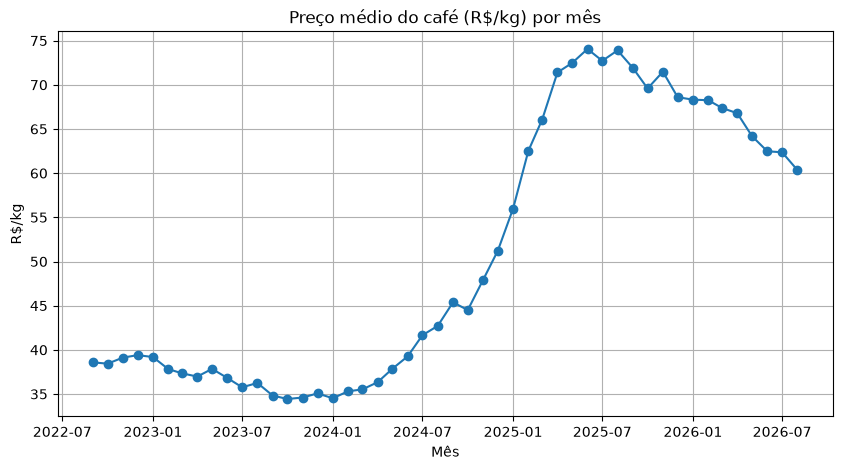

In [294]:
plt.figure(figsize=(10, 5))
plt.plot(mensal.index, mensal.values, marker="o")
plt.title("Preço médio do café (R$/kg) por mês")
plt.xlabel("Mês")
plt.ylabel("R$/kg")
plt.grid(True)

Lembrando que no caso os valores tem que ser dividos por 2 ja que todos os pacotes tem 500g

In [295]:
mensal = (cafe.groupby("mes_ano_data")["ppk"].mean())/2
print(mensal.describe())

count    48.000000
mean     25.370098
std       7.517482
min      17.218696
25%      18.625918
50%      21.804250
75%      33.465997
max      37.027073
Name: ppk, dtype: float64


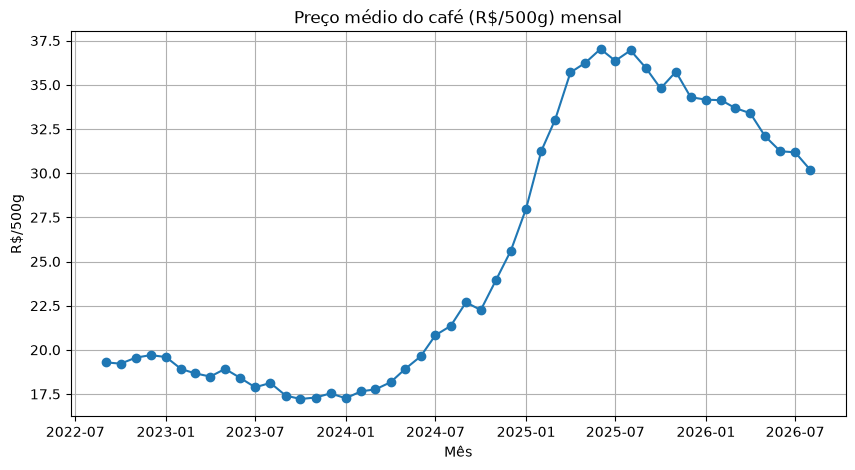

In [296]:
plt.figure(figsize=(10, 5))
plt.plot(mensal.index, mensal.values, marker="o")
plt.title("Preço médio do café (R$/500g) mensal")
plt.xlabel("Mês")
plt.ylabel("R$/500g")
plt.grid(True)

O grafico não mudou nada no quesito visual, apenas diminiu o a escala por 2 ja que todos os pacotes analisados na base dados é de 500g

Aqui pegando uma visão individual de cada café que nos fez realmente tirar o resto dos muito abaixos em qauntidades.

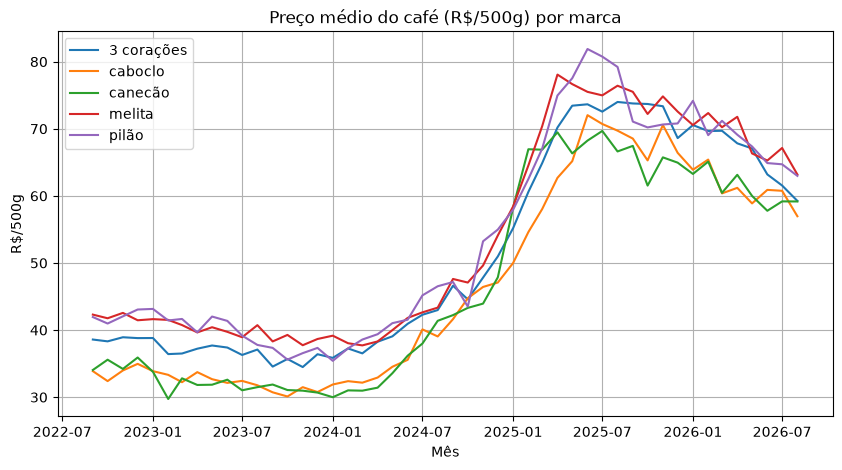

In [297]:
mensal_marca = cafe.groupby(["mes_ano_data", "marca"])["ppk"].mean().unstack()
plt.figure(figsize=(10, 5))
for marca in mensal_marca.columns:
    plt.plot(mensal_marca.index, mensal_marca[marca], label=marca)

plt.title("Preço médio do café (R$/500g) por marca")
plt.xlabel("Mês")
plt.ylabel("R$/500g")
plt.legend()
plt.grid(True)
plt.show()

### Produção de café (Conab)

Com algumas pesquisas no google, esses anos tiveram muitos efeitos climaticos que ocasiona a alta e baixa no preço do café (EL NINÕ) é uma delas
Para mostrar graficamente pegamos dados oficiais da CONAB que mostra os dados das safras de cafe anualmente.

In [298]:
# Dados oficiais da Conab consolidados (2022 a 2026)
dados_conab = {
    "Ano": [2022, 2023, 2024, 2025, 2026, 2027],
    "Prod_Total_Milhoes_Sacas": [50.9, 55.1, 54.2, 56.5, 67.6, 65.0],
    "Prod_Arabica_Milhoes_Sacas": [32.7, 38.9, 39.6, 35.8, 48.2, 43.5],
    "Prod_Conilon_Milhoes_Sacas": [18.2, 16.2, 14.6, 20.7, 19.4, 21.5],
    "Ciclo_Bienal_Arabica": ["Alta", "Baixa", "Alta (Quebra Climática)", "Baixa", "Alta (Recorde)", "Baixa (Previsão)"],
    "Variacao_Anual_Total_%": [6.7, 8.2, -1.6, 4.2, 19.6, -3.8]
}

conab = pd.DataFrame(dados_conab)
conab.columns = conab.columns.str.lower().str.strip()

<module 'matplotlib.pyplot' from '/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/matplotlib/pyplot.py'>

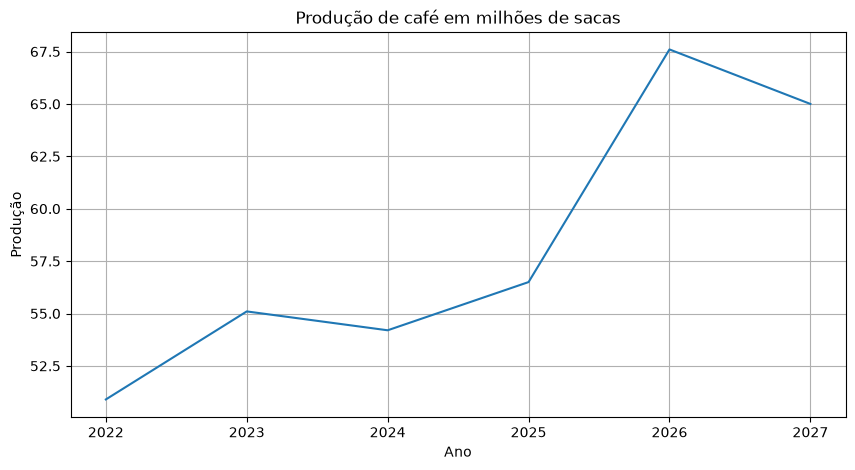

In [299]:
plt.figure(figsize=(10, 5))
plt.plot(conab["ano"], conab["prod_total_milhoes_sacas"], label="Total")
plt.grid(True)
plt.title("Produção de café em milhões de sacas")
plt.xlabel("Ano")
plt.ylabel("Produção")
plt

plotando os 2 graficos juntos para ver a oposição

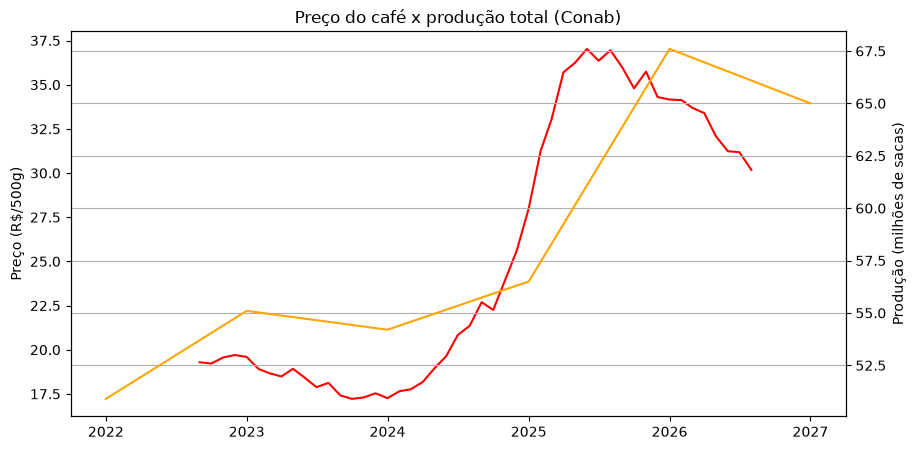

In [300]:
conab["ano"] = pd.to_datetime(conab["ano"].astype(str), format="%Y")
fig, ax1 = plt.subplots(figsize=(10, 5))


ax1.plot(mensal.index, mensal.values, color="red")
ax1.set_ylabel("Preço (R$/500g)")

ax2 = ax1.twinx()
ax2.plot(conab["ano"], conab["prod_total_milhoes_sacas"], color="orange")   # marker deixa claro que são pontos anuais
ax2.set_ylabel("Produção (milhões de sacas)")
plt.title("Preço do café x produção total (Conab)")
plt.grid(True)
plt.show()

Aqui podemos ver que o clima realmente é o fator decisivo em sua variabilidade de preço, pois quando a sagra cresce o preço diminui e vice versa

### Análise da série: autocorrelação, decomposição STL e estacionariedade

Antes de escolher o modelo de suavização exponencial, analisamos se a série do preço médio mensal (R$/500g) tem tendência, sazonalidade e se é estacionária.

- **Análise de autocorrelação**

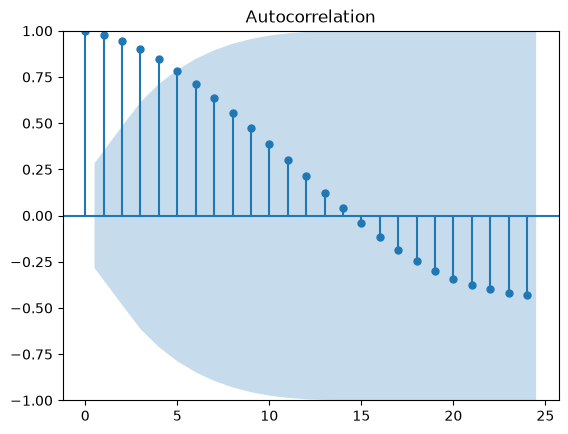

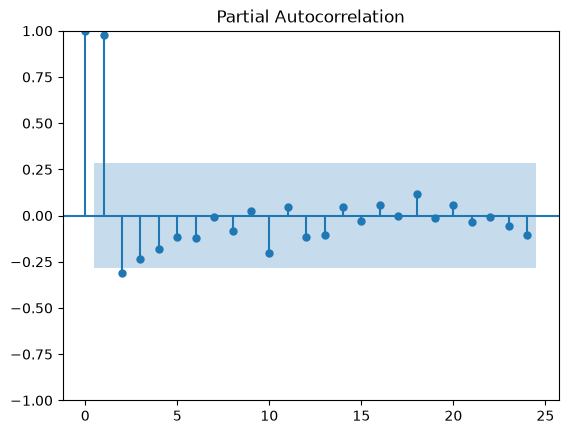

In [301]:
serie = mensal.asfreq("MS") # define frequência no inicio de cada Mês


plot_acf(serie, lags=24)
plt.show()

plot_pacf(serie, lags=24)
plt.show()

A autocorrelação começa bem perto de 1 no lag 1 e cai devagar, sem nenhum pico no lag 12. Isso indica uma série com tendência e sem sazonalidade anual marcada.

### Decomposição da série (STL)

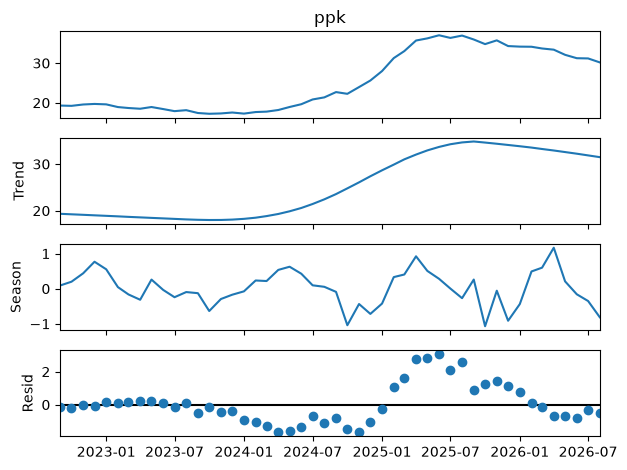

In [302]:
stl = STL(serie, period=12)
res = stl.fit()
res.plot()
plt.show()

Tendência: estável em torno de R$19 / R$20 até meados de 2024, sobe até cerca de R$ 35 em meados de 2025 e depois cai devagar até aproximadamente R$30 em 2026.

Sazonalidade: oscila só entre aproximadamente −R$1 e +R$1, e não repete o mesmo desenho todo ano. Não dá para afirmar que existe sazonalidade.

Resíduo: fica alto durante a alta de 2025, porque o preço subiu mais rápido do que a tendência suavizada consegue acompanhar.

In [303]:
result = adfuller(serie.values)
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
print('Critical Values:')
for key, value in result[4].items():
  print('\t%s: %.3f' % (key,value))

ADF Statistic: -1.279741
p-value: 0.638389
Critical Values:
	1%: -3.593
	5%: -2.932
	10%: -2.604


/tmp/ipykernel_110507/2529066374.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(serie.values)


A estatística do teste (−1,28) é maior que todos os valores críticos (−3,59; −2,93; −2,60) e o p-value (0,64) está longe de zero. Portanto, a série tem indícios de não ser estacionária.

Conclusão: a série tem tendência, não tem sazonalidade expressiva e não é estacionária.

### Predição do preço para os próximos meses

2026-09-01    29.763792
2026-10-01    29.295314
2026-11-01    28.891457
2026-12-01    28.543307
2027-01-01    28.243182
2027-02-01    27.984455
2027-03-01    27.761416
2027-04-01    27.569144
2027-05-01    27.403393
2027-06-01    27.260506
2027-07-01    27.137329
2027-08-01    27.031142
Freq: MS, Name: simulation, dtype: float64


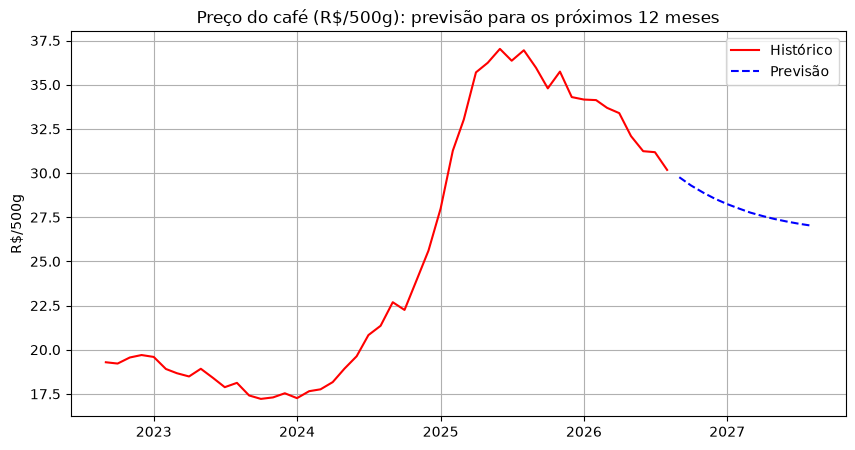

In [304]:
serie = mensal.asfreq("MS") #mensal

# Modelo de Holt com tendência aditiva amortecida, seasonal=None porque a ACF e o STL não mostraram sazonalidade
modelo = ETSModel(serie, error="add", trend="add", damped_trend=True)
resultado = modelo.fit()


previsao = resultado.forecast(12) # Proximo ano (2027)
print(previsao)


plt.figure(figsize=(10, 5))
plt.plot(serie.index, serie.values, label="Histórico", color="red")
plt.plot(previsao.index, previsao.values, label="Previsão", color="blue", linestyle="--")
plt.title("Preço do café (R$/500g): previsão para os próximos 12 meses")
plt.ylabel("R$/500g")
plt.legend()
plt.grid(True)
plt.show()

### Validação do modelo

Para saber se o ETS é útil, comparamos com um baseline ingênuo: a predição com shift(1), ou seja, prever que o preço do próximo mês é igual ao do mês atual. Se o modelo não errar menos que isso, ele não serve.

São 24 folds na validação cruzada, cada um com uma previsão de 1 mês à frente (horizonte h = 1). A métrica é o RMSE, em R$/500g.

In [305]:
ingenuo = serie.shift(1)


n_treino = 24  # os 24 primeiros meses formam o menor treino
ets_pred = dict()
for i in range(n_treino, len(serie)):
    treino = serie.iloc[:i].copy()
    ets = ETSModel(treino, error="add", trend="add", damped_trend=True).fit(disp=False)
    ets_pred[serie.index[i]] = ets.forecast(1).iloc[0]

validacao = pd.DataFrame({"Real": serie.iloc[n_treino:], "ETS": pd.Series(ets_pred), "Ingenuo": ingenuo.iloc[n_treino:]})
validacao["Erro_ETS"] = validacao["Real"] - validacao["ETS"]
validacao["Erro_Ingenuo"] = validacao["Real"] - validacao["Ingenuo"]

RMSE_ets = np.sqrt(sum(validacao["Erro_ETS"]**2)/len(validacao))
RMSE_ingenuo = np.sqrt(sum(validacao["Erro_Ingenuo"]**2)/len(validacao))
print("RMSE ETS =", RMSE_ets.round(3))
print("RMSE ingênuo =", RMSE_ingenuo.round(3))
print(f"O ETS errou menos que o ingênuo em {(validacao['Erro_ETS'].abs() < validacao['Erro_Ingenuo'].abs()).sum()} de {len(validacao)} meses")

RMSE ETS = 1.06
RMSE ingênuo = 1.369
O ETS errou menos que o ingênuo em 17 de 24 meses


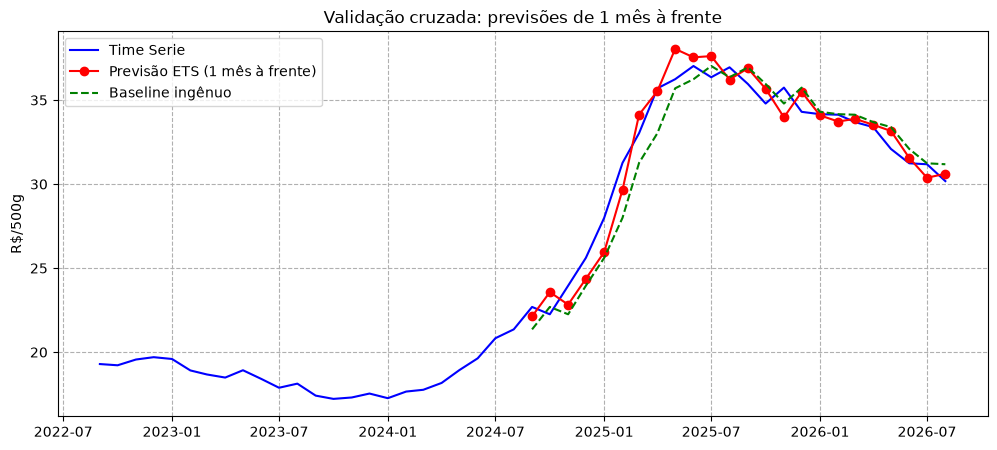

In [306]:
plt.figure(figsize=(12,5))
plt.plot(serie, color="Blue", label="Time Serie")
plt.plot(validacao["ETS"], color="Red", marker="o", label="Previsão ETS (1 mês à frente)")
plt.plot(validacao["Ingenuo"], color="Green", linestyle="--", label="Baseline ingênuo")
plt.title("Validação cruzada: previsões de 1 mês à frente")
plt.ylabel("R$/500g")
plt.grid(linestyle="--")
plt.legend()
plt.show()

O ETS teve RMSE de R$ 1,06, contra R$ 1,37 do baseline ingênuo.

Conclusão: o ETS supera o baseline ingênuo no geral e é útil para prever o próximo mês.

A validação foi feita prevendo 1 mês à frente, então esse erro vale para a previsão do próximo mês. A previsão de 12 meses feita acima não foi validada e serve só como ilustração da tendência.

### Juntando as 3 informações

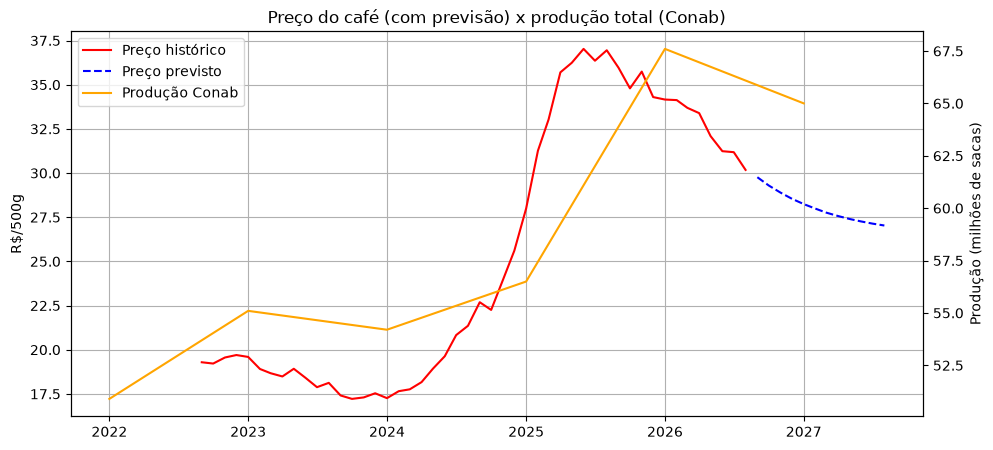

In [307]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(serie.index, serie.values, label="Preço histórico", color="red")
ax1.plot(previsao.index, previsao.values, label="Preço previsto", color="blue", linestyle="--")
ax1.set_ylabel("R$/500g")


ax2 = ax1.twinx()
ax2.plot(conab["ano"], conab["prod_total_milhoes_sacas"],
         label="Produção Conab" , color="orange")
ax2.set_ylabel("Produção (milhões de sacas)")

linhas1, nomes1 = ax1.get_legend_handles_labels()
linhas2, nomes2 = ax2.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, nomes1 + nomes2, loc="upper left")

plt.title("Preço do café (com previsão) x produção total (Conab)")
ax1.grid(True)
plt.show()

### Conclusão

No começo do trabalho achavamos que a variabilidade do preço do café viria principalmente das taxas de impostos, mas a análise da série mostrou outra coisa.

A série tem uma tendência forte, não encontramos sazonalidade e pelo teste ADF, a série não é estacionária.

Na validação cruzada, prevendo 1 mês à frente, o modelo teve RMSE de R$1,06, contra R$1,37 do baseline ingênuo. Ou seja, é possível prever o preço do próximo mês com um erro de cerca de R$1. A previsão para os próximos 12 meses aponta uma queda leve, mas ela não foi validada e serve só como ilustração.

O modelo usa apenas o histórico de preços. Fatores externos como o clima (El Niño) e o tamanho da safra, que vimos nos dados da Conab, parecem ter puxado a alta de 2025, mas não entram no modelo. Uma quebra de safra, por exemplo, pode mudar o preço de um jeito que o histórico não consegue prever.

### Referências

https://www.canalrural.com.br/agricultura/cafe/cafe-riscos-climaticos-sustentam-precos-apesar-de-perspectiva-favoravel-no-brasil/



https://www.gov.br/conab/pt-br/atuacao/informacoes-agropecuarias/safras/safra-de-cafe/safra-de-cafe-1


## 3. Pergunta 2: Agrupamentos (mercados de melhores preços)

### Valores irreais e preço relativo

In [308]:
years = df["Mes_Ano_Data"].dt.year.unique()

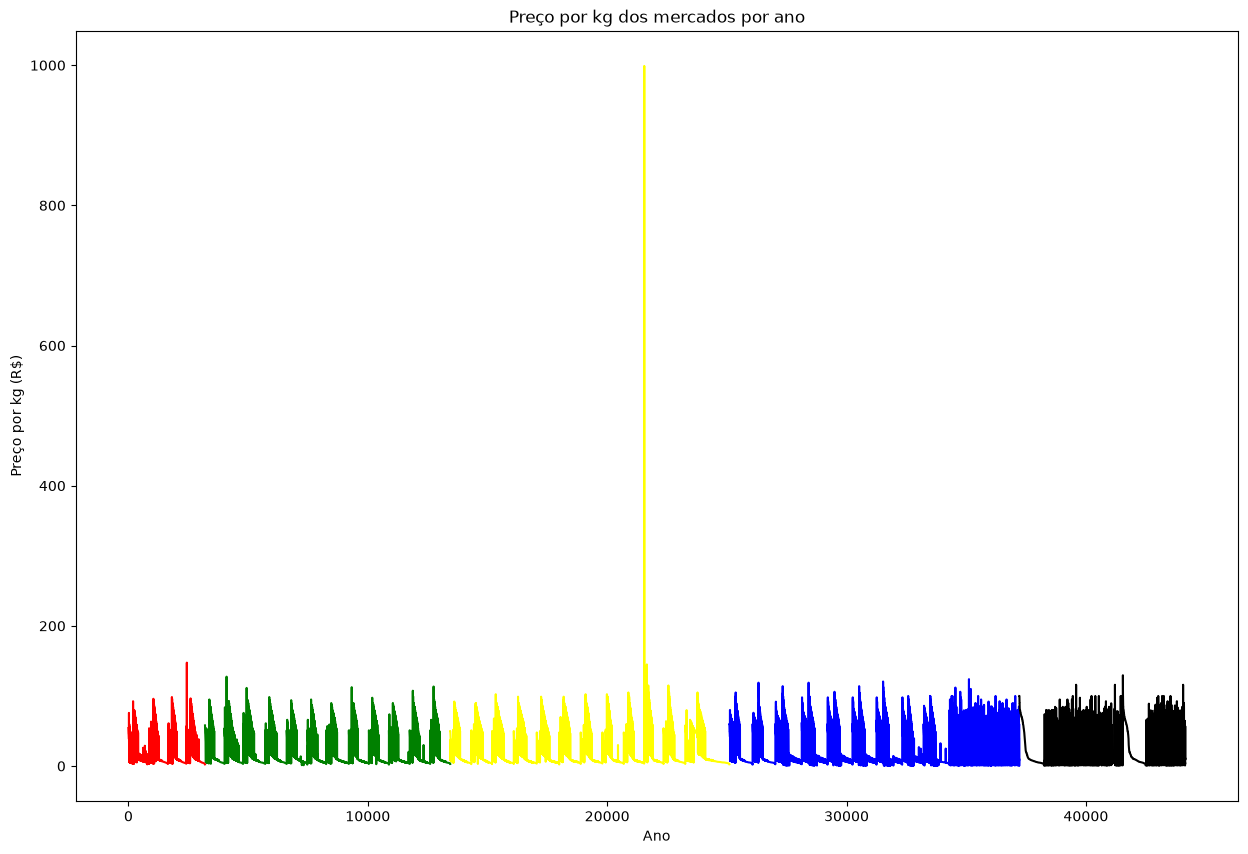

In [309]:
color = ["red","green","yellow","blue","black"]
plt.figure(figsize=(15, 10))
plt.title("Preço por kg dos mercados por ano")
for c, y in enumerate(years):
    plt.plot(df[df["Mes_Ano_Data"].dt.year == y]["PPK"], color = color[c])
plt.xlabel("Ano")
plt.ylabel("Preço por kg (R$)");

Percebemos que existe alguns valores irreais, como preço de carnes saindo à R$0.00 ou uma banana nanica saindo à R$1000.00. Por isso, decidimos criar um dataframe sem esses valores.

In [310]:
df_2 = df.copy()

In [311]:
for produto in df_2["Produto"].unique():
    mediana = df_2[df_2["Produto"] == produto]["PPK"].median()
    irreais = (df_2["Produto"] == produto) & ((df_2["PPK"] > mediana * 3) | (df_2["PPK"] < mediana / 3))
    df_2 = df_2[~irreais]

In [312]:
# quanto o preço está acima/abaixo do "normal" daquele produto naquele mês
# interpretação: 1.0 = na mediana, 0.9 = 10% mais barato, 1.2 = 20% mais caro
mediana_mes = df_2.groupby(["Produto", "Mes_Ano_Data"])["PPK"].transform("median")
df_2["PPK_Relativo"] = df_2["PPK"] / mediana_mes


Criamos uma nova coluna para lidar com possíveis flutuações de preço em um mesmo ano no KMeans. (Exemplo: os preços subirem em Dezembro pode tornar ele um mercado caro na clusterização, mesmo que durante o resto do ano os preços eram estáveis.)

In [313]:
df_2

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK,PPK_Relativo
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20,1.180828
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90,1.174292
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99,1.132680
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90,1.130719
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49,1.100000
...,...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99,1.052659
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50,0.920746
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90,1.023565
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99,0.430144


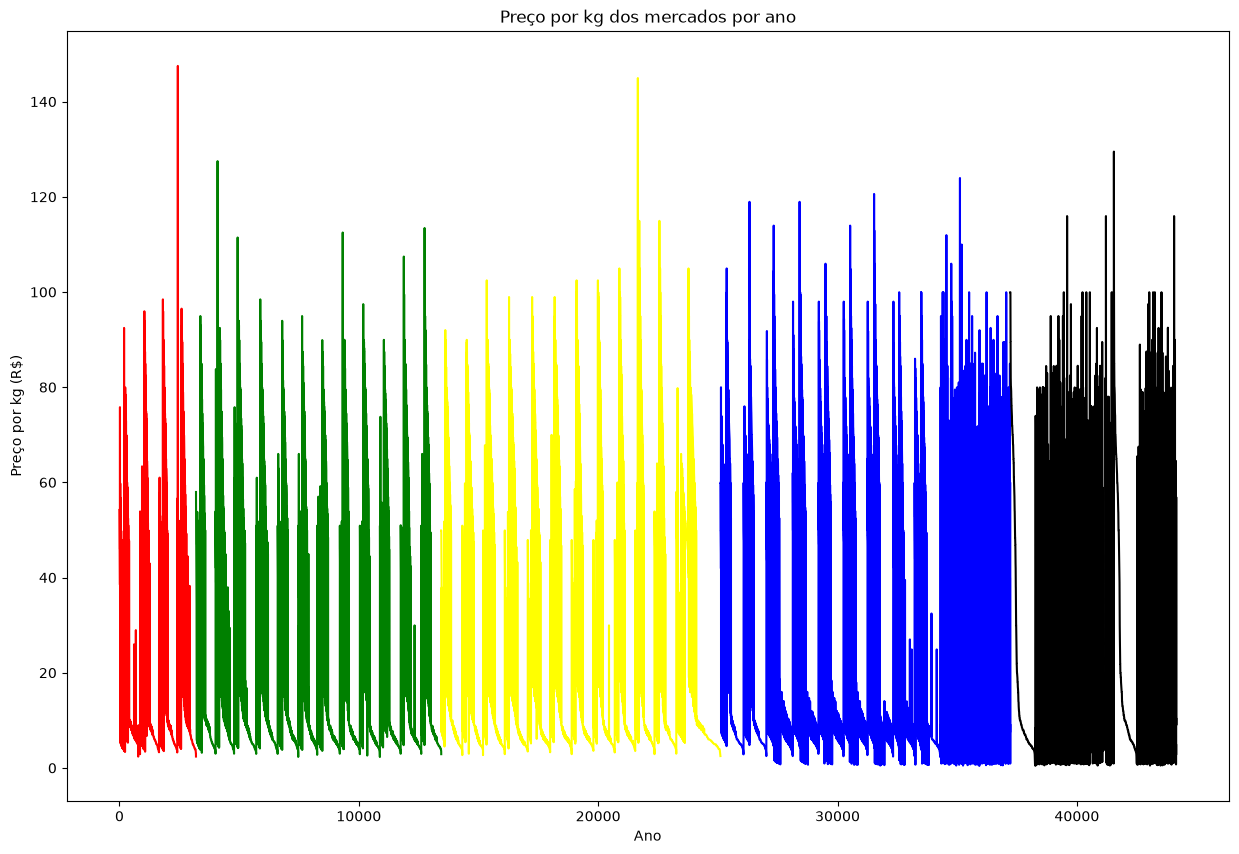

In [314]:
color = ["red","green","yellow","blue","black"]
plt.figure(figsize=(15, 10))
plt.title("Preço por kg dos mercados por ano")
for c, y in enumerate(years):
    plt.plot(df_2[df_2["Mes_Ano_Data"].dt.year == y]["PPK"], color = color[c])
plt.xlabel("Ano")
plt.ylabel("Preço por kg (R$)");

### KMeans por produto e ano (exemplo: arroz)

In [315]:
df_2.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
                     'Pão',                 'Farinha',
                  'Feijão',                    'Óleo',
            'Banana Prata',                   'Leite',
                  'Açúcar',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
                  'Pernil',        'Frango Sobrecoxa',
                     'Ovo',                'Macarrão',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra']
Length: 23, dtype: str

In [316]:
produto_escolhido = "arroz".title()
df_produto = df_2[df_2["Produto"] == produto_escolhido]

df_2022 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2022]
df_2023 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2023]
df_2024 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2024]
df_2025 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2025]
df_2026 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2026]

dfs_ano = [df_2022, df_2023, df_2024, df_2025, df_2026]

for df_ano in dfs_ano:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_ano[["PPK_Relativo"]])

    # 3. Criar e treinar o modelo K-Means (exemplo com K=3)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)

    # 4. Obter os rótulos (clusters) de cada linha
    centros = kmeans.cluster_centers_.ravel()
    ordem = sorted(range(3), key=lambda c: centros[c])
    novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
    df_ano['cluster'] = [novo_rotulo[l] for l in kmeans.labels_]

    # Ver os centroides finais
    print(kmeans.cluster_centers_)

[[ 0.14414088]
 [-1.13290461]
 [ 1.3701328 ]]
[[-0.0308362 ]
 [-1.34251659]
 [ 1.15413646]]
[[ 1.14758704]
 [-1.31190648]
 [ 0.0049619 ]]
[[ 1.05443382]
 [-1.5334763 ]
 [-0.12763359]]
[[-1.38948745]
 [ 1.07993874]
 [-0.05431386]]


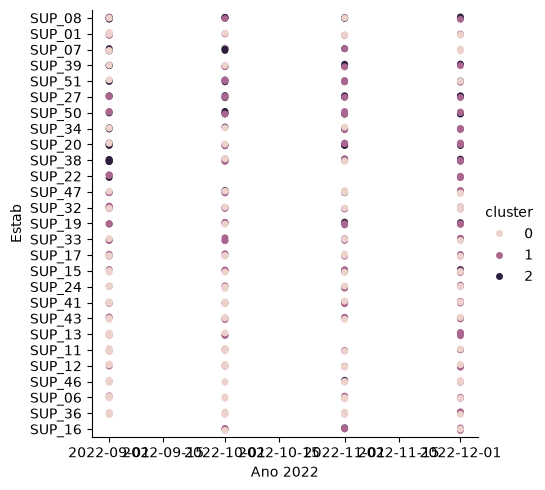

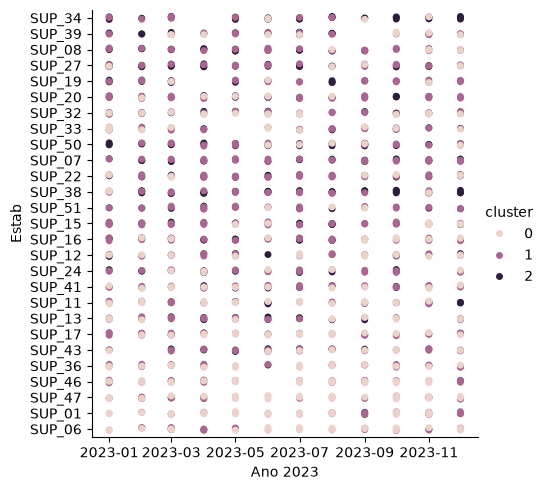

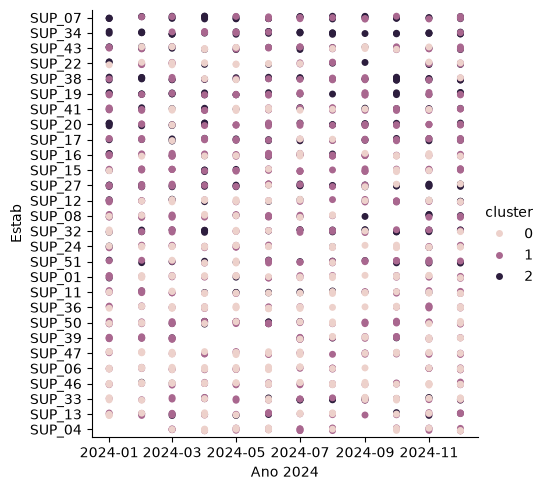

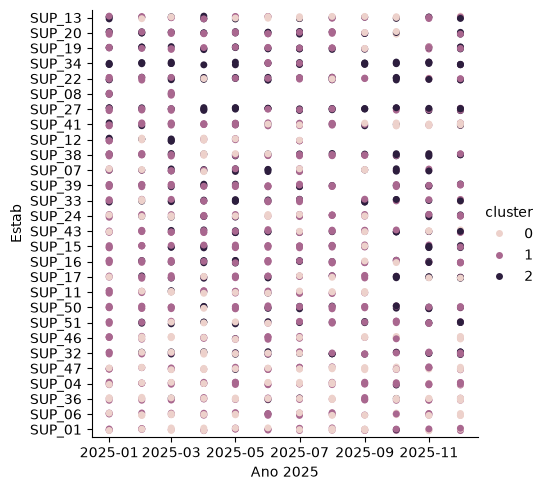

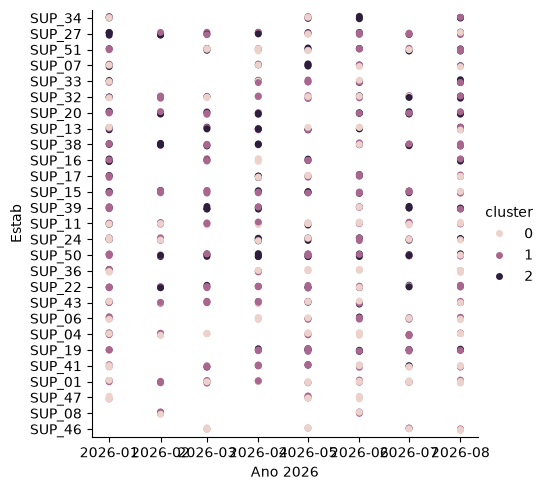

In [317]:
for y, df_ano in enumerate(dfs_ano):
    # sns.scatterplot(data = df_2[df_2["Mes_Ano_Data"].dt.year == y], x = "Mes_Ano_Data", y = "Preco", hue="")
    sns.catplot(data = df_ano, x = "Mes_Ano_Data", y = "Estab", hue="cluster")
    plt.xlabel(f"Ano {years[y]}")
    plt.show()

### Ranking dos mercados

In [318]:
# alguns estabelecimentos podem vender diferentes marcas
# levando em consideracao que +marcas e -preco = melhor mercado com ofertas
def melhor_mercado(dados: pd.DataFrame, grupo: int) -> list[str]:
    """
    Grupos: 
        0 - mais barato
        1 - preço médio
        2 - mais caros
    """
    estab_mais_aparecem: dict[str, int] = {}
    dados_filtrado = dados[dados["cluster"] == grupo]
    
    if dados_filtrado.empty:
        return []
        
    for estab in dados_filtrado["Estab"]:
        if estab not in estab_mais_aparecem:
            estab_mais_aparecem[estab] = 1
        else:
            estab_mais_aparecem[estab] += 1

    maior_qntd_ofertas = max(estab_mais_aparecem.values())
    melhores_estabs = [
        estab for estab, qntd in estab_mais_aparecem.items() if qntd == maior_qntd_ofertas
    ]
    
    return melhores_estabs


In [319]:
def melhor_mercado_pelo_produto(dados: pd.DataFrame, produto: str, ano: int, grupo: int, coluna:str = "Produto") -> tuple[list[str], str]:
    try:
        produto_escolhido = produto
        dados_produto = dados[dados[coluna] == produto_escolhido]
        dados_ano = dados_produto[dados_produto["Mes_Ano_Data"].dt.year == ano].copy()
        
        #proteção contra poucos dados para o número de clusters do K-Means
        total_amostras = dados_ano.shape[0]
        if total_amostras == 0:
            return (["nenhum"], produto)
            
        n_clusters = 3 if total_amostras >= 3 else total_amostras
        
        scaler = StandardScaler()
        x_scaled = scaler.fit_transform(dados_ano[["PPK_Relativo"]])

        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
        kmeans.fit(x_scaled)

        centros = kmeans.cluster_centers_.ravel()
        ordem = sorted(range(n_clusters), key=lambda c: centros[c])
        novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
        dados_ano['cluster'] = [novo_rotulo[l] for l in kmeans.labels_]

        return (melhor_mercado(dados_ano, grupo), produto)
        
    except Exception as e:
        return (["nenhum"], produto)


In [320]:
def melhor_mercado_todos_produtos(dados:pd.DataFrame, ano:int, grupo:int, coluna:str = "Produto", mostrar_rank:bool = False)->dict[str,list[str]]|None:
    estab_mais_aparecem:dict[str,list[str]] = {}
    produtos:list[str] = list(dados[coluna].dropna().unique())
    produtos_do_ano:list[str] = list(dados[dados["Mes_Ano_Data"].dt.year == ano][coluna].dropna().unique())
    for p in produtos:
        if(p in produtos_do_ano):
            mercados, produto = melhor_mercado_pelo_produto(dados, p, ano, grupo, coluna)
            for m in mercados:
                if(m not in estab_mais_aparecem):
                    estab_mais_aparecem[m] = [produto]
                else:
                    estab_mais_aparecem[m].append(produto)
    estab_mais_aparecem = dict(
        sorted(estab_mais_aparecem.items(), key=lambda item: len(item[1]), reverse=True)
    )
    if(mostrar_rank):
        print(f"Melhores mercados de {ano}:")
        for i, e in enumerate(estab_mais_aparecem):
            print(f" {i+1}° - {e}:\n\tItens: {', '.join(estab_mais_aparecem[e])}")
    return estab_mais_aparecem

In [321]:
def melhor_mercado_todos_anos(dados: pd.DataFrame, grupo: int, coluna:str = "Produto",mostrar_rank: bool = False) -> dict[str, int]|None:
    """
    Mostra o mercado que mais vezes foi o 'melhor do ano' ao longo de todos os anos.
    """
    estab_mais_aparecem: dict[str, int] = {}
    anos_lista = sorted(dados["Mes_Ano_Data"].dt.year.unique())
    
    for ano in anos_lista:
        mercados_dict = melhor_mercado_todos_produtos(dados, ano, grupo, coluna)

        if not mercados_dict:
            continue
        
        primeiro_mercado = list(mercados_dict.keys())[0]
        if primeiro_mercado not in estab_mais_aparecem:
            estab_mais_aparecem[primeiro_mercado] = 1  # primeira vez que aparece na história dos anos
        else:
            estab_mais_aparecem[primeiro_mercado] += 1 # apareceu em mais um ano
    
    if(mostrar_rank):
        estab_mais_aparecem = dict(
            sorted(estab_mais_aparecem.items(), key=lambda item: item[1], reverse=True)
        )
        print("Mercados:")
        for mercado, vitorias in estab_mais_aparecem.items():
            if grupo == 2:
                print(f"- {mercado}: Foi caro em {vitorias} ano(s)")
            if grupo == 1:
                print(f"- {mercado}: Foi 'mediano' em {vitorias} ano(s)")
            if grupo == 0:
                print(f"- {mercado}: Foi barato em {vitorias} ano(s)")
        return None
    else:
        return estab_mais_aparecem


Se posto "melhor_mercado_todos_produtos(df_2, 2026, 0)", veremos que o Supermercado 04 e o Supermercado 01 empataram com 7 itens de baixo preço cada, mas em produtos diferentes: o Supermercado 04 se destaca em Arroz, Café, Pão, Farinha e Frango Sobrecoxa, e o Supermercado 01 em Feijão, Açúcar, Carne Bovina Acem, Ovo e Macarrão. Os dois têm Manteiga e Óleo baratos.

In [322]:
melhor_mercado_todos_produtos(df_2, 2026, 0, mostrar_rank = True)

Melhores mercados de 2026:
 1° - SUP_04:
	Itens: Manteiga, Arroz, Café, Pão, Farinha, Óleo, Frango Sobrecoxa
 2° - SUP_01:
	Itens: Manteiga, Feijão, Óleo, Açúcar, Carne Bovina Acem, Ovo, Macarrão
 3° - SUP_43:
	Itens: Tomate, Banana Nanica, Batata, Frango Sobrecoxa, Ovo
 4° - SUP_36:
	Itens: Arroz, Frango Peito, Pernil
 5° - SUP_11:
	Itens: Arroz, Banana Prata, Leite
 6° - SUP_24:
	Itens: Carne Bovina Coxão Mole, Frango Peito
 7° - SUP_41:
	Itens: Banana Nanica, Batata


{'SUP_04': ['Manteiga',
  'Arroz',
  'Café',
  'Pão',
  'Farinha',
  'Óleo',
  'Frango Sobrecoxa'],
 'SUP_01': ['Manteiga',
  'Feijão',
  'Óleo',
  'Açúcar',
  'Carne Bovina Acem',
  'Ovo',
  'Macarrão'],
 'SUP_43': ['Tomate', 'Banana Nanica', 'Batata', 'Frango Sobrecoxa', 'Ovo'],
 'SUP_36': ['Arroz', 'Frango Peito', 'Pernil'],
 'SUP_11': ['Arroz', 'Banana Prata', 'Leite'],
 'SUP_24': ['Carne Bovina Coxão Mole', 'Frango Peito'],
 'SUP_41': ['Banana Nanica', 'Batata']}

Uma conclusão sobre qual mercado é o melhor durante os anos pode se tornar imprecisa por depender da quantidade de amostras feitas pelos anos, se o mercado foi visitado no ano, ou se ele existiu desde 2022 (primeiro ano de coleta), o que pode tornar a resposta enviesada por ocorrência.

In [323]:
melhor_mercado_todos_anos(df_2, 2, mostrar_rank = True)

/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_33: Foi caro em 2 ano(s)
- SUP_32: Foi caro em 2 ano(s)
- SUP_16: Foi caro em 1 ano(s)


Existem alguns mercados que acabarão sendo os mais baratos por serem os únicos ou um dos poucos que vendem o produto.

In [324]:
melhor_mercado_todos_anos(df_2, 0, mostrar_rank = True)

/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_04: Foi barato em 2 ano(s)
- SUP_12: Foi barato em 1 ano(s)
- SUP_06: Foi barato em 1 ano(s)
- SUP_43: Foi barato em 1 ano(s)


### Filtro genérico

- Implementando Filtro (Carne Bovina -> Carne, Frango Coxão -> Frango, Pão Francês -> Pão)

In [325]:
def adicionar_filtro(dados:pd.DataFrame)->pd.DataFrame:
    produtos_unitarios:list[str] = dados["Produto"].unique()
    lista_unitarios:list[str] = []
    for p in produtos_unitarios:
        if(search(r" ", p)):
            lista = p.split()[0]
            if(lista not in lista_unitarios):
                lista_unitarios.append(lista)
        else:
            if(p not in lista_unitarios):
                lista_unitarios.append(p)

    padrao_regex = "^(" + "|".join(lista_unitarios) + ")"
    dados["Produto_Filtro"] = dados["Produto"].str.extract(padrao_regex)
    dados.loc[dados["Produto"] == "Pernil", "Produto_Filtro"] = "Carne"
    return dados

df_2 = adicionar_filtro(df_2)

- Exibindo os melhores mercados com um filtro genérico, podemos ver que as classificações mudaram. Antes encontraríamos o Supermercado 33, junto ao 32, como os de preço alto durante 2 anos, mas quando pomos os nomes dos alimentos para algo genérico, vemos que nenhum nesta categoria foi o maior no ranking.

In [326]:
melhor_mercado_todos_anos(df_2, 2, "Produto", True)

/home/giugarrido/Área de trabalho/Faculdade/dados_cesta_basica/.venv/lib/python3.13/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_33: Foi caro em 2 ano(s)
- SUP_32: Foi caro em 2 ano(s)
- SUP_16: Foi caro em 1 ano(s)


In [327]:
# com filtro
# melhor_mercado_todos_produtos(df_2, 2022, 0, "Produto_Filtro")
melhor_mercado_todos_anos(df_2, 2, "Produto_Filtro", True)

Mercados:
- SUP_33: Foi caro em 1 ano(s)
- SUP_16: Foi caro em 1 ano(s)
- SUP_38: Foi caro em 1 ano(s)
- SUP_34: Foi caro em 1 ano(s)
- SUP_32: Foi caro em 1 ano(s)


### Validação do ranking

Validação do ranking: para saber se um mercado é barato de verdade, e não só por acaso nos meses coletados, verificamos se o nível de preço de cada mercado se mantém de um ano para o outro.

Usamos o PPK_Relativo porque ele já tira a diferença de preço entre os produtos e o efeito da inflação. Para cada mercado e ano, calculamos a mediana do PPK_Relativo de cada produto e depois a mediana entre os produtos, assim os produtos com mais marcas não pesam mais.

In [328]:
# Para cada mercado e ano: mediana do PPK_Relativo de cada produto e depois a mediana entre os produtos
# assim cada produto pesa igual, não importa quantas marcas ele tenha
dados = df_2.copy()
dados["Ano"] = dados["Mes_Ano_Data"].dt.year

mediana_produto = dados.groupby(["Ano", "Estab", "Produto"])["PPK_Relativo"].median()
nivel_mercado = mediana_produto.groupby(["Ano", "Estab"]).median().unstack("Ano")
nivel_mercado.round(3)

Ano,2022,2023,2024,2025,2026
Estab,,,,,
SUP_01,0.890,0.882,0.899,0.889,0.867
SUP_04,NaN,NaN,0.879,0.877,0.860
SUP_06,0.883,0.903,0.846,0.884,0.839
SUP_07,1.090,1.119,1.113,1.062,1.073
SUP_08,1.032,1.018,1.000,1.031,0.930
SUP_11,0.943,0.978,0.968,0.954,0.962
SUP_12,0.960,0.977,0.965,0.981,NaN
SUP_13,1.012,1.045,1.011,1.011,0.954
SUP_15,1.049,1.059,1.063,1.114,1.131


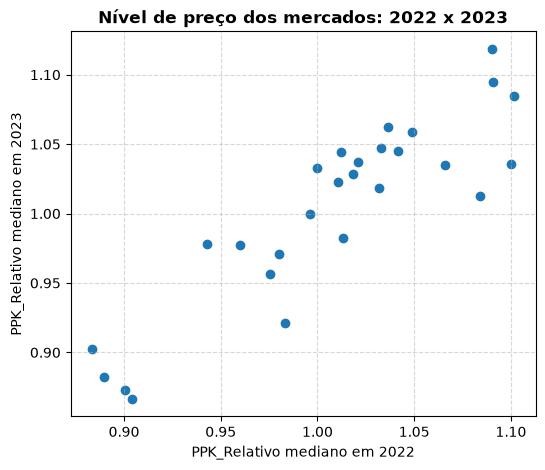

2022 -> 2023
r = 0.89
p-valor = 0.000000
mercados = 27
Existe correlação linear: os mercados mantêm o nível de preço de um ano para o outro



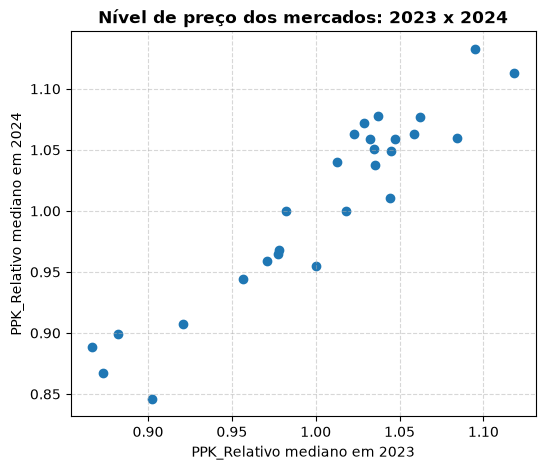

2023 -> 2024
r = 0.94
p-valor = 0.000000
mercados = 27
Existe correlação linear: os mercados mantêm o nível de preço de um ano para o outro



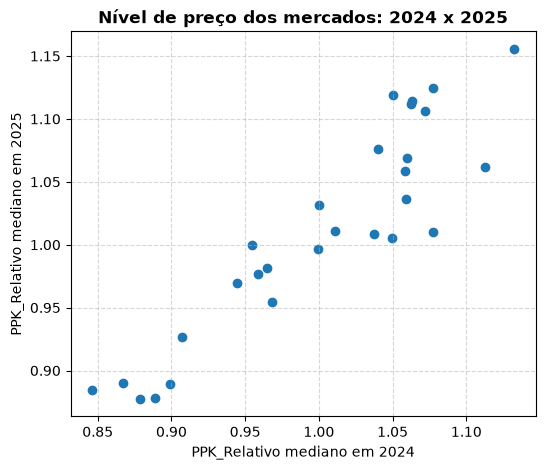

2024 -> 2025
r = 0.92
p-valor = 0.000000
mercados = 28
Existe correlação linear: os mercados mantêm o nível de preço de um ano para o outro



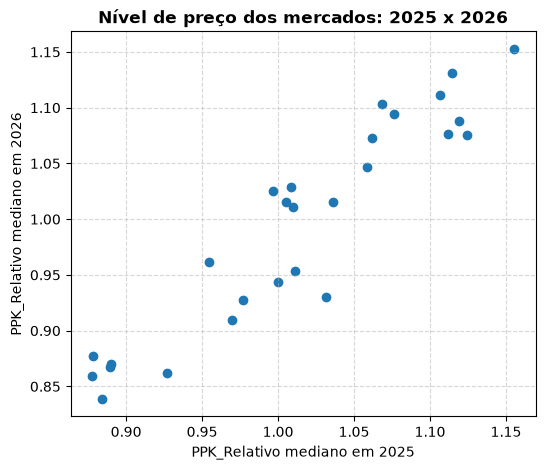

2025 -> 2026
r = 0.94
p-valor = 0.000000
mercados = 27
Existe correlação linear: os mercados mantêm o nível de preço de um ano para o outro



In [334]:
anos = nivel_mercado.columns

for i in range(len(anos) - 1):
    # Para calcular o coeficiente de correlação, não pode haver células vazias
    pares = nivel_mercado[[anos[i], anos[i + 1]]].dropna()

    plt.figure(figsize=(6, 5))
    plt.scatter(pares[anos[i]], pares[anos[i + 1]])
    plt.title(f"Nível de preço dos mercados: {anos[i]} x {anos[i + 1]}", fontweight="bold")
    plt.xlabel(f"PPK_Relativo mediano em {anos[i]}")
    plt.ylabel(f"PPK_Relativo mediano em {anos[i + 1]}")
    plt.grid(linestyle="--", alpha=0.5)
    plt.show()

    r, p_valor = pearsonr(pares[anos[i]], pares[anos[i + 1]])
    print(f"{anos[i]} -> {anos[i + 1]}")
    print(f"r = {r:.2f}")
    print(f"p-valor = {p_valor:.6f}")
    print(f"mercados = {len(pares)}")

    # H0: Não existe correlação linear entre os anos. Se p <= 0,05, rejeitamos H0
    if p_valor <= 0.05:
        print("Existe correlação linear: os mercados mantêm o nível de preço de um ano para o outro\n")
    else:
        print("Não há evidência de correlação linear\n")

Em todos os pares de anos a correlação foi alta (r entre 0,89 e 0,94) e o p-valor ficou muito abaixo de 0,05. Ou seja, um mercado que é barato em um ano continua barato no ano seguinte, e o mesmo vale para os caros. Isso mostra que existem mercados consistentemente baratos ou caros, e que o resultado não é só sorte da amostra.

### Conclusão

In [330]:
# Nível médio de cada mercado em todos os anos, do mais barato para o mais caro
nivel_mercado.mean(axis=1).sort_values().round(3)

Estab
SUP_06    0.871
SUP_04    0.872
SUP_46    0.880
SUP_47    0.883
SUP_01    0.886
SUP_36    0.920
SUP_41    0.951
SUP_11    0.961
SUP_43    0.963
SUP_12    0.971
SUP_24    0.979
SUP_08    1.002
SUP_17    1.003
SUP_13    1.006
SUP_22    1.029
SUP_50    1.031
SUP_51    1.039
SUP_39    1.042
SUP_38    1.049
SUP_19    1.057
SUP_33    1.062
SUP_16    1.067
SUP_20    1.067
SUP_32    1.072
SUP_15    1.083
SUP_27    1.084
SUP_07    1.091
SUP_34    1.125
dtype: float64

Os mercados mais baratos em todos os anos são o SUP_06, SUP_04, SUP_46, SUP_47 e SUP_01, entre 11% e 13% abaixo da mediana. Os mais caros são o SUP_34, SUP_07, SUP_27, SUP_15 e SUP_3.

Esse resultado é parecido, mas não igual, ao do melhor_mercado_todos_anos: lá o SUP_33 aparecia como um dos mais caros, mas pelo nível de preço ele não está entre os 5 mais caros. Isso acontece porque as funções de ranking contam quantas linhas de cada mercado caem no grupo, e não quanto o mercado cobra a mais ou a menos.